# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

**Scenario.** A taxi (matatu) association runs 14-seater vehicles on three routes out of Kampala. It wants to forecast demand, understand fares, and decide how many vehicles to deploy.

Reusable logic lives in `src/taxiroute.py` (`Route`, `Forecaster` and its subclasses, and helper functions).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.taxiroute import (
    ExponentialSmoothingForecaster,
    LinearTrendForecaster,
    MovingAverageForecaster,
    Route,
    SeasonalNaiveForecaster,
    grid_search_alpha,
    simulate_weekly_demand,
    solve_equilibrium,
    vehicles_needed,
    walk_forward_mae,
)

SEED = 11
ROUTE_COLORS = {"Ntinda": "#0072B2", "Entebbe": "#D55E00", "Mukono": "#009E73"}

## Task 1 — `Route` class

In [2]:
routes = {
    "Ntinda": Route("Ntinda", [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], fare=2000),
    "Entebbe": Route("Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], fare=5000),
    "Mukono": Route("Mukono", [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], fare=3000),
}

for r in routes.values():
    print(r)
    stats = r.stats()
    print(f"  passenger stats: mean={stats['mean']:.1f}, variance={stats['variance']:.1f}, stdev={stats['stdev']:.2f}")
    print(f"  total revenue (10 days): UGX {r.total_revenue():,.0f}")

Route('Ntinda', fare=2000, days=10)
  passenger stats: mean=47.4, variance=54.3, stdev=7.37
  total revenue (10 days): UGX 948,000
Route('Entebbe', fare=5000, days=10)
  passenger stats: mean=67.8, variance=45.1, stdev=6.71
  total revenue (10 days): UGX 3,390,000
Route('Mukono', fare=3000, days=10)
  passenger stats: mean=52.0, variance=26.4, stdev=5.14
  total revenue (10 days): UGX 1,560,000


## Task 2 — Supply-demand equilibrium, Ntinda route

Qd = 120 − 0.02P, Qs = 10 + 0.03P, written as a 2×2 linear system and solved with `scipy.linalg.solve`.

In [3]:
q_star, p_star = solve_equilibrium(a=120, b=0.02, c=10, d=0.03)
print(f"Equilibrium: P* = UGX {p_star:,.0f}, Q* = {q_star:.1f} passengers/trip-hour")
print(f"Current fare: UGX 2,000 -> {'below' if 2000 < p_star else 'above'} equilibrium")

Equilibrium: P* = UGX 2,200, Q* = 76.0 passengers/trip-hour
Current fare: UGX 2,000 -> below equilibrium


**Interpretation.** The equilibrium fare (UGX 2,200) is above the current UGX 2,000 fare, so the route is **underpriced relative to the model's equilibrium**: at UGX 2,000, quantity demanded (120 − 0.02×2000 = 80) exceeds quantity supplied (10 + 0.03×2000 = 70) — a shortage of about 10 passengers/trip-hour. This is consistent with the everyday experience of matatus filling up quickly and touts negotiating fares upward during peak periods: the posted fare sits below the price that would actually clear the market, so operators have room to raise fares (or add capacity) before demand and supply balance.

## Task 3 — `Forecaster` base class and three subclasses

(a) 3-day moving average, (b) simple exponential smoothing with tunable α, (c) linear trend — all sharing a `fit()` / `predict(horizon)` interface.

In [4]:
demo_series = routes["Ntinda"].passengers
print("3-day MA forecast:", MovingAverageForecaster(window=3).fit(demo_series).predict(1))
print("Exp. smoothing (a=0.3) forecast:", ExponentialSmoothingForecaster(alpha=0.3).fit(demo_series).predict(1))
print("Linear trend forecast:", LinearTrendForecaster().fit(demo_series).predict(1))

3-day MA forecast: [48.]
Exp. smoothing (a=0.3) forecast: [47.95470654]
Linear trend forecast: [53.66666667]


## Task 4 — Walk-forward backtesting (days 4–10) and alpha grid search

In [5]:
START = 3  # 0-indexed day 4
ALPHAS = [round(a, 1) for a in np.arange(0.1, 1.0, 0.1)]

results = []
best_alpha_by_route = {}
for name, route in routes.items():
    series = route.passengers
    best_alpha, es_mae = grid_search_alpha(series, start=START, alphas=ALPHAS)
    best_alpha_by_route[name] = best_alpha
    ma_mae = walk_forward_mae(lambda: MovingAverageForecaster(window=3), series, start=START)
    trend_mae = walk_forward_mae(lambda: LinearTrendForecaster(), series, start=START)
    results.append({
        "route": name,
        "3-day MA MAE": ma_mae,
        f"Exp. smoothing MAE (best a={best_alpha})": es_mae,
        "Linear trend MAE": trend_mae,
    })

mae_table = pd.DataFrame(results).set_index("route")
mae_table.round(2)

,3-day MA MAE,Exp. smoothing MAE (best a=0.9),Linear trend MAE
route,,,
Ntinda,7.52,5.88,7.87
Entebbe,7.19,4.73,7.71
Mukono,5.33,3.79,6.39


In [6]:
best_model_name = {}
for row in results:
    name = row["route"]
    scores = {
        "MovingAverage": row["3-day MA MAE"],
        "ExpSmoothing": row[f"Exp. smoothing MAE (best a={best_alpha_by_route[name]})"],
        "LinearTrend": row["Linear trend MAE"],
    }
    best_model_name[name] = min(scores, key=scores.get)
    print(f"{name}: best model = {best_model_name[name]} (MAE={scores[best_model_name[name]]:.2f})")

Ntinda: best model = ExpSmoothing (MAE=5.88)
Entebbe: best model = ExpSmoothing (MAE=4.73)
Mukono: best model = ExpSmoothing (MAE=3.79)


## Task 5 — Forecast day 11 with the best model per route

In [7]:
def make_model(model_name: str, alpha: float):
    if model_name == "MovingAverage":
        return MovingAverageForecaster(window=3)
    if model_name == "ExpSmoothing":
        return ExponentialSmoothingForecaster(alpha=alpha)
    return LinearTrendForecaster()

day11_passenger_forecast = {}
day11_revenue_forecast = {}
for name, route in routes.items():
    model = make_model(best_model_name[name], best_alpha_by_route[name]).fit(route.passengers)
    forecast_passengers = float(model.predict(1)[0])
    day11_passenger_forecast[name] = forecast_passengers
    day11_revenue_forecast[name] = forecast_passengers * route.fare
    print(f"{name}: day 11 forecast = {forecast_passengers:.1f} passengers -> UGX {day11_revenue_forecast[name]:,.0f} revenue")

Ntinda: day 11 forecast = 45.2 passengers -> UGX 90,494 revenue
Entebbe: day 11 forecast = 64.2 passengers -> UGX 321,137 revenue
Mukono: day 11 forecast = 50.1 passengers -> UGX 150,376 revenue


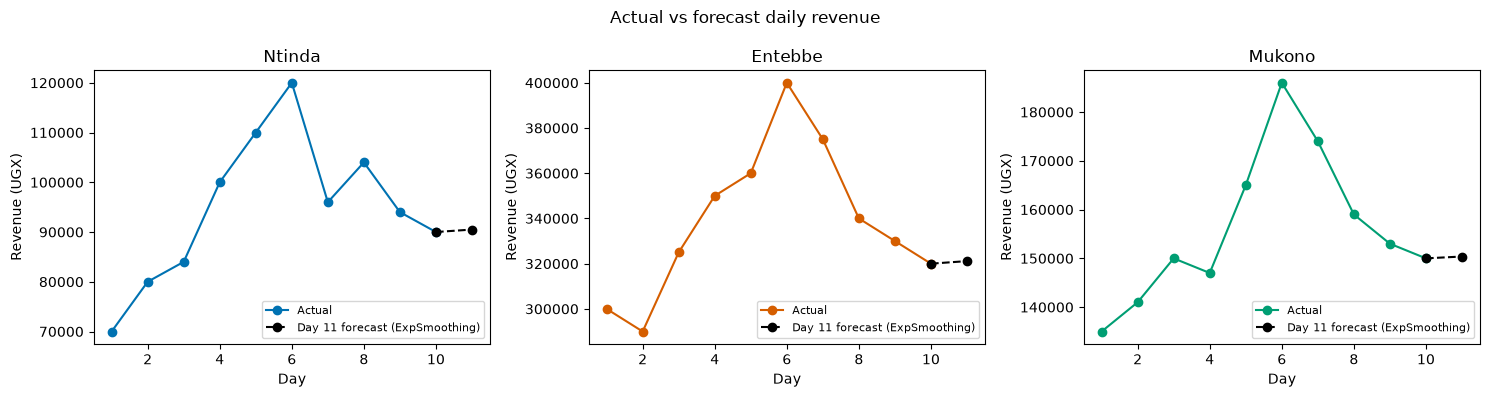

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, (name, route) in zip(axes, routes.items()):
    days = list(range(1, 11))
    ax.plot(days, route.daily_revenue(), marker="o", color=ROUTE_COLORS[name], label="Actual")
    ax.plot([10, 11], [route.daily_revenue()[-1], day11_revenue_forecast[name]],
            marker="o", linestyle="--", color="black", label=f"Day 11 forecast ({best_model_name[name]})")
    ax.set_title(name)
    ax.set_xlabel("Day")
    ax.set_ylabel("Revenue (UGX)")
    ax.legend(fontsize=8)
fig.suptitle("Actual vs forecast daily revenue")
fig.tight_layout()
plt.show()

## Task 6 — Fleet planning for day 11

Each vehicle makes 8 one-way trips/day at 14 passengers (112 passenger-trips/day capacity), plus a 15% buffer.

In [9]:
for name, forecast in day11_passenger_forecast.items():
    n_vehicles = vehicles_needed(forecast, trips_per_day=8, seats=14, buffer=0.15)
    print(f"{name}: forecast {forecast:.1f} passengers -> deploy {n_vehicles} vehicle(s) on day 11")

Ntinda: forecast 45.2 passengers -> deploy 1 vehicle(s) on day 11
Entebbe: forecast 64.2 passengers -> deploy 1 vehicle(s) on day 11
Mukono: forecast 50.1 passengers -> deploy 1 vehicle(s) on day 11


## Extension — 60 days with a weekly pattern: does seasonal-naive beat the moving average?

Simulate 60 days of Ntinda-like demand with a realistic weekly shape (busiest Friday, quietest Sunday) and noise, then compare walk-forward MAE for `SeasonalNaiveForecaster` (season_length=7) against the 3-day moving average.

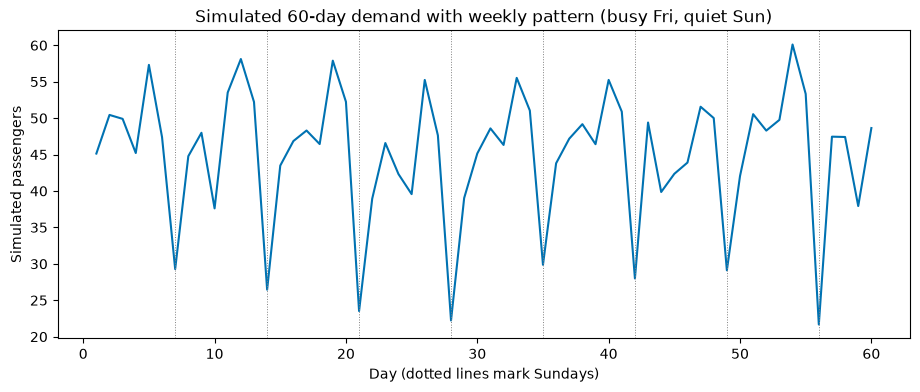

In [10]:
weekly_series = simulate_weekly_demand(base_mean=45, n_days=60, noise_std=4.0, seed=SEED)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range(1, 61), weekly_series, color=ROUTE_COLORS["Ntinda"])
for sunday in range(7, 61, 7):
    ax.axvline(sunday, color="grey", linestyle=":", linewidth=0.7)
ax.set_xlabel("Day (dotted lines mark Sundays)")
ax.set_ylabel("Simulated passengers")
ax.set_title("Simulated 60-day demand with weekly pattern (busy Fri, quiet Sun)")
plt.show()

In [11]:
EXT_START = 7  # need at least 7 points of history for the seasonal-naive model

ma_mae_60 = walk_forward_mae(lambda: MovingAverageForecaster(window=3), weekly_series, start=EXT_START)
seasonal_mae_60 = walk_forward_mae(lambda: SeasonalNaiveForecaster(season_length=7), weekly_series, start=EXT_START)
best_alpha_60, es_mae_60 = grid_search_alpha(weekly_series, start=EXT_START, alphas=ALPHAS)

print(f"3-day moving average MAE: {ma_mae_60:.2f}")
print(f"Exponential smoothing MAE (best a={best_alpha_60}): {es_mae_60:.2f}")
print(f"Seasonal-naive (7-day) MAE: {seasonal_mae_60:.2f}")
print(f"\nSeasonal-naive beats moving average: {seasonal_mae_60 < ma_mae_60}")

3-day moving average MAE: 7.80
Exponential smoothing MAE (best a=0.1): 7.07
Seasonal-naive (7-day) MAE: 4.04

Seasonal-naive beats moving average: True


## Findings & Limitations

Exponential smoothing won the walk-forward backtest on all three 10-day routes (MAE 3.79–5.88 vs 5.33–7.87 for the moving average and 6.39–7.87 for linear trend), and the grid search always picked the boundary value **α=0.9** — the model wants to weight the most recent day almost entirely, which makes sense for a 10-day series but is a red flag worth naming: the search only tested α∈[0.1, 0.9], so the true optimum may sit even higher, and with just 7 backtested points per route the "best" α is not estimated very precisely. The supply-demand model says Ntinda's UGX 2,000 fare sits below its UGX 2,200 equilibrium (a ~10 passenger/trip-hour shortage) — a plausible explanation for why matatus on this route fill quickly, though the demand/supply slopes themselves are given, not estimated from real elasticity data, so the exact equilibrium number should be read as illustrative of direction, not a precise pricing recommendation. Day-11 forecasts (45–64 passengers per route) translate to just 1 vehicle needed per route even with the 15% buffer, reflecting how far below a single 14-seater's 112-passenger daily capacity these illustrative volumes sit — a real association's fleet math would look different at realistic city-scale ridership. The extension is the most instructive result: over 60 simulated days with a genuine weekly pattern, the 7-day seasonal-naive forecaster (MAE 4.04) beat both the moving average (7.80) and exponential smoothing (7.07, this time with the *opposite* boundary α=0.1) — confirming that once real seasonality exists, only a model that explicitly encodes it can exploit that structure; averaging methods just blend Friday's peak and Sunday's trough into a mediocre forecast for both. The 10-day core-task series is too short to reveal this at all, which is itself a limitation of that dataset.